# 14. Propagación, Refracción, Difracción y Corrientes (`sedmor.propagation`)

Este cuaderno aplica el módulo `sedmor.propagation` para analizar la transformación física del oleaje al propagarse desde aguas profundas hacia estructuras y zonas costeras:

1. **Relación de dispersión con corriente** (`dispersion_with_current`): efecto Doppler $(\omega_a - k\,U_\parallel)^2 = g\,k\tanh(k\,h)$ y límite de **bloqueo por corriente opuesta** (*wave blocking*).
2. **Propagación 1D en perfil batimétrico** (`propagate_wave_profile`): someramiento, refracción por ley de Snell, conservación del flujo de acción con corrientes, disipación por fricción y rotura límite $H \le \gamma_b\,h$.
3. **Difracción en obras marítimas** (`diffraction_semi_infinite_breakwater`, `diffraction_breakwater_gap`, `diffraction_random_directional`): solución exacta de Sommerfeld / Penney y Price (1952) y difracción espectral direccional de Goda (1978, 2000).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110


## 1. Efecto de la corriente en la relación de dispersión y *wave blocking*

Evaluamos un oleaje de período $T = 8.0\,\text{s}$ en profundidad $h = 15.0\,\text{m}$ sujeto a velocidades paralelas $U_\parallel$ entre $-3.5\,\text{m/s}$ (corriente en contra) y $+2.5\,\text{m/s}$ (corriente a favor).


Sin corriente (U=0): L=81.89 m | cg=7.50 m/s
A favor (U=+1.5 m/s): L=97.10 m | σ/ω=0.878
En contra (U=-1.5 m/s): L=63.78 m | σ/ω=1.188
Bloqueo por corriente opuesta (cg + U <= 0) para U_|| <= -3.12 m/s


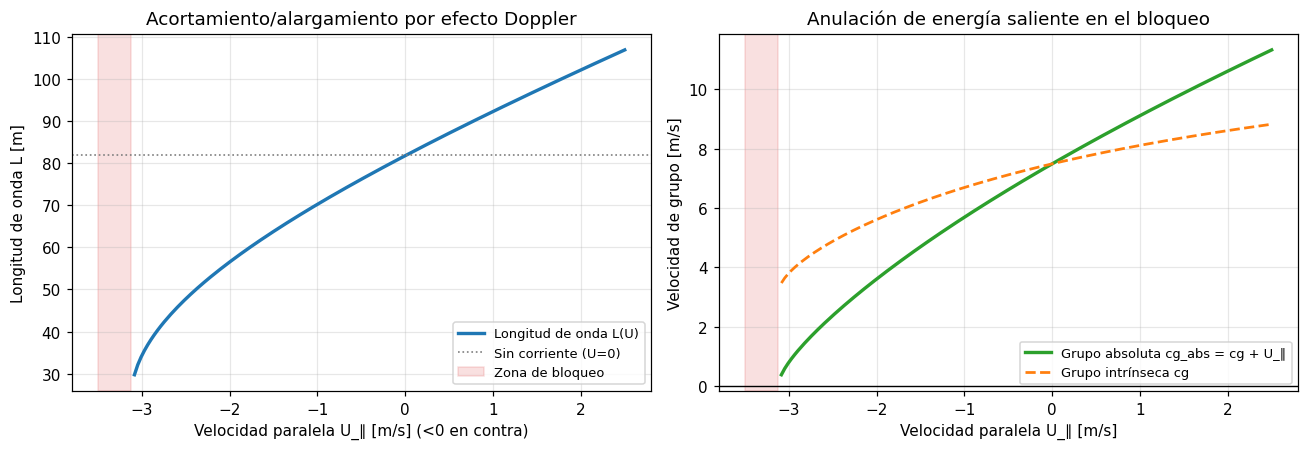

In [2]:
T = 8.0
h = 15.0
u_vals = np.linspace(-3.5, 2.5, 160)
disp = sm.propagation.dispersion_with_current(h=h, T=T, U=u_vals, current_angle_deg=0.0)

u_blk = u_vals[disp.is_blocked]
idx_zero = int(np.argmin(np.abs(u_vals)))
idx_pos = int(np.argmin(np.abs(u_vals - 1.5)))
idx_neg = int(np.argmin(np.abs(u_vals + 1.5)))

print(f"Sin corriente (U=0): L={disp.L[idx_zero]:.2f} m | cg={disp.cg_abs[idx_zero]:.2f} m/s")
print(f"A favor (U=+1.5 m/s): L={disp.L[idx_pos]:.2f} m | σ/ω={disp.sigma_intrinsic[idx_pos]/disp.omega_abs[idx_pos]:.3f}")
print(f"En contra (U=-1.5 m/s): L={disp.L[idx_neg]:.2f} m | σ/ω={disp.sigma_intrinsic[idx_neg]/disp.omega_abs[idx_neg]:.3f}")
if u_blk.size > 0:
    print(f"Bloqueo por corriente opuesta (cg + U <= 0) para U_|| <= {np.max(u_blk):.2f} m/s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ok = ~disp.is_blocked
ax1.plot(u_vals[ok], disp.L[ok], lw=2.2, color="tab:blue", label="Longitud de onda L(U)")
ax1.axhline(disp.L[idx_zero], color="gray", ls=":", lw=1.1, label="Sin corriente (U=0)")
if u_blk.size > 0:
    ax1.axvspan(u_vals[0], np.max(u_blk), color="tab:red", alpha=0.14, label="Zona de bloqueo")
ax1.set_xlabel("Velocidad paralela U_∥ [m/s] (<0 en contra)")
ax1.set_ylabel("Longitud de onda L [m]")
ax1.set_title("Acortamiento/alargamiento por efecto Doppler")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.5)

ax2.plot(u_vals[ok], disp.cg_abs[ok], lw=2.2, color="tab:green", label="Grupo absoluta cg_abs = cg + U_∥")
ax2.plot(u_vals[ok], disp.cg_intrinsic[ok], "--", lw=1.8, color="tab:orange", label="Grupo intrínseca cg")
ax2.axhline(0.0, color="k", lw=0.9)
if u_blk.size > 0:
    ax2.axvspan(u_vals[0], np.max(u_blk), color="tab:red", alpha=0.14)
ax2.set_xlabel("Velocidad paralela U_∥ [m/s]")
ax2.set_ylabel("Velocidad de grupo [m/s]")
ax2.set_title("Anulación de energía saliente en el bloqueo")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 2. Propagación 1D: someramiento, refracción por Snell, fricción y corriente opuesta

Propagamos $H_0 = 2.6\,\text{m}$, $T = 10.0\,\text{s}$ entrando desde aguas profundas con ángulo oblicuo $\theta_0 = 32^\circ$ sobre una pendiente costera uniforme ($h$ de $18\,\text{m}$ a $1.2\,\text{m}$ en $800\,\text{m}$). Comparamos el caso sin fricción ni corriente, el caso con rugosidad $k_s = 0.04\,\text{m}$ y el caso con un chorro de reflujo saliente ($U_x = -0.8\,\text{m/s}$).


Sin corriente/fricción -> rotura en x=687 m (h_b=3.58 m, H_b=2.79 m, θ_b=11.3°)
Con reflujo opuesto     -> rotura en x=660 m (h_b=4.14 m, H_b=3.23 m, θ_b=10.5°)


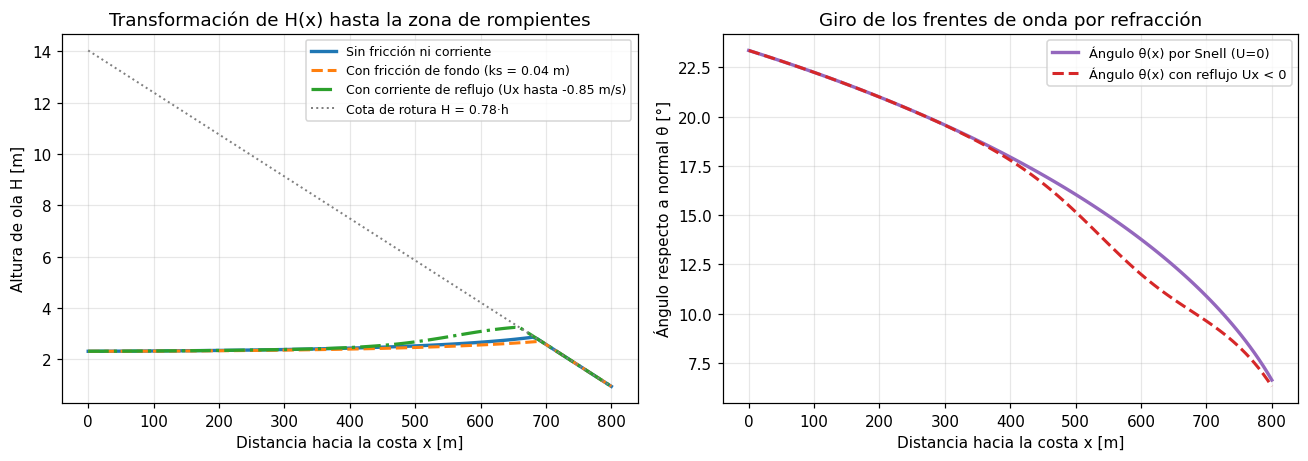

In [3]:
x = np.linspace(0.0, 800.0, 121)
depth = 18.0 - 0.021 * x
# Chorro de reflujo concentrado en la zona somera (U_x < 0 hacia mar abierto)
ux_ebb = -0.85 * np.exp(-((x - 620.0) / 140.0) ** 2)

p_base = sm.propagation.propagate_wave_profile(x, depth, H0=2.6, T=10.0, theta0_deg=32.0, gamma_b=0.78)
p_fric = sm.propagation.propagate_wave_profile(x, depth, H0=2.6, T=10.0, theta0_deg=32.0, k_s=0.04, gamma_b=0.78)
p_ebb = sm.propagation.propagate_wave_profile(x, depth, H0=2.6, T=10.0, theta0_deg=32.0, U_x=ux_ebb, gamma_b=0.78)

print(
    f"Sin corriente/fricción -> rotura en x={p_base.breaking_x:.0f} m "
    f"(h_b={p_base.breaking_depth:.2f} m, H_b={p_base.breaking_H:.2f} m, θ_b={p_base.breaking_angle_deg:.1f}°)"
)
print(
    f"Con reflujo opuesto     -> rotura en x={p_ebb.breaking_x:.0f} m "
    f"(h_b={p_ebb.breaking_depth:.2f} m, H_b={p_ebb.breaking_H:.2f} m, θ_b={p_ebb.breaking_angle_deg:.1f}°)"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.plot(x, p_base.H, lw=2.2, label="Sin fricción ni corriente")
ax1.plot(x, p_fric.H, "--", lw=2.0, label="Con fricción de fondo (ks = 0.04 m)")
ax1.plot(x, p_ebb.H, "-.", lw=2.1, label="Con corriente de reflujo (Ux hasta -0.85 m/s)")
ax1.plot(x, 0.78 * depth, ":", color="gray", lw=1.3, label="Cota de rotura H = 0.78·h")
ax1.set_xlabel("Distancia hacia la costa x [m]")
ax1.set_ylabel("Altura de ola H [m]")
ax1.set_title("Transformación de H(x) hasta la zona de rompientes")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.2)

ax2.plot(x, p_base.theta_deg, lw=2.2, color="tab:purple", label="Ángulo θ(x) por Snell (U=0)")
ax2.plot(x, p_ebb.theta_deg, "--", lw=2.0, color="tab:red", label="Ángulo θ(x) con reflujo Ux < 0")
ax2.set_xlabel("Distancia hacia la costa x [m]")
ax2.set_ylabel("Ángulo respecto a normal θ [°]")
ax2.set_title("Giro de los frentes de onda por refracción")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 3. Difracción 2D detrás de dique semi-infinito y bocana portuaria

Calculamos campos espaciales bidimensionales de $K_d = H/H_{\text{inc}}$ con la solución exacta de Penney y Price (1952) para longitud de onda $L = 60\,\text{m}$: (a) dique semi-infinito con incidencia oblicua de $70^\circ$ y (b) bocana entre dos diques ($B = 2.5\,L$), además de comparar el perfil abrigado monocromático con la difracción irregular direccional de Goda ($s_{\max} = 10$ y $s_{\max} = 75$).


En y=2L, x=+2.5L (sombra): Kd_mono=0.150 | Kd_Goda(s=75)=0.155 | Kd_Goda(s=10)=0.213


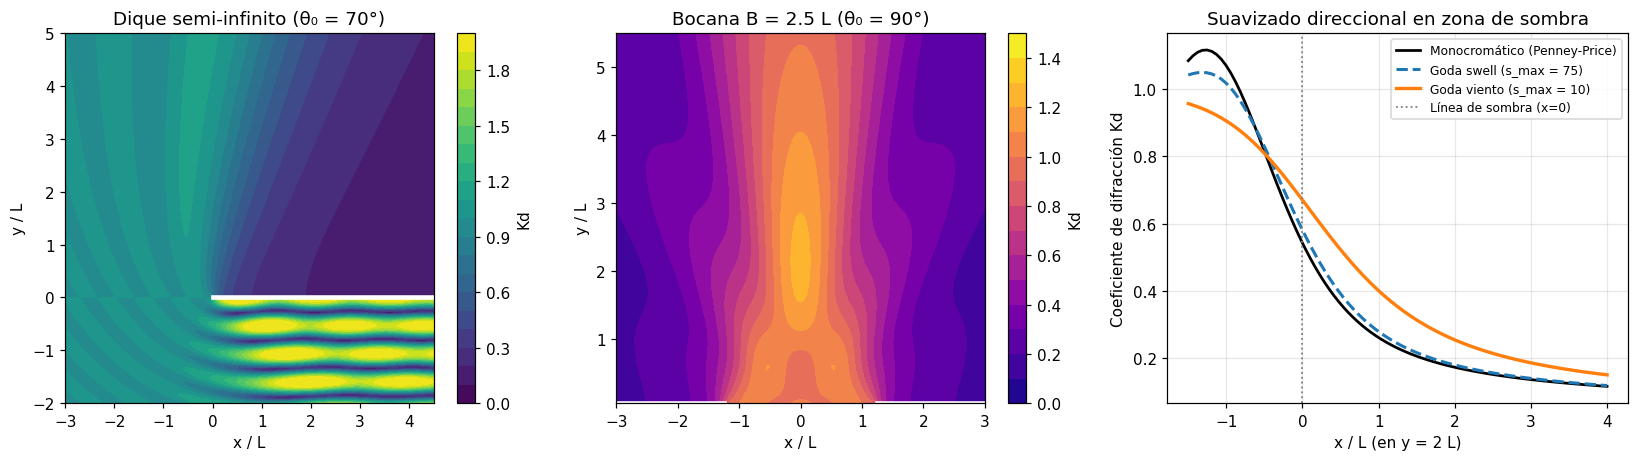

In [4]:
L = 60.0
# Malla 1: dique semi-infinito en x >= 0, y = 0
xg = np.linspace(-3.0 * L, 4.5 * L, 160)
yg = np.linspace(-2.0 * L, 5.0 * L, 160)
X, Y = np.meshgrid(xg, yg)
# Evitar evaluar exactamente sobre la línea singular del dique (y=0, x>=0)
Y_safe = np.where((np.abs(Y) < 1e-3) & (X >= 0.0), 1e-3, Y)
dif_semi = sm.propagation.diffraction_semi_infinite_breakwater(X, Y_safe, L=L, wave_angle_deg=70.0)

# Malla 2: bocana B = 2.5 L en y >= 0
B = 2.5 * L
xb = np.linspace(-3.0 * L, 3.0 * L, 160)
yb = np.linspace(0.05 * L, 5.5 * L, 150)
XB, YB = np.meshgrid(xb, yb)
dif_gap = sm.propagation.diffraction_breakwater_gap(XB, YB, L=L, gap_width=B, wave_angle_deg=90.0)

# Perfil transversal detrás del dique semi-infinito en y = 2 L: monocromático vs Goda
x_prof = np.linspace(-1.5 * L, 4.0 * L, 90)
y_prof = np.full_like(x_prof, 2.0 * L)
kd_mono = sm.propagation.diffraction_semi_infinite_breakwater(x_prof, y_prof, L=L, wave_angle_deg=90.0).Kd
kd_s10 = sm.propagation.diffraction_random_directional(x_prof, y_prof, L=L, wave_angle_deg=90.0, s_max=10.0)
kd_s75 = sm.propagation.diffraction_random_directional(x_prof, y_prof, L=L, wave_angle_deg=90.0, s_max=75.0)

print(f"En y=2L, x=+2.5L (sombra): Kd_mono={kd_mono[65]:.3f} | Kd_Goda(s=75)={kd_s75[65]:.3f} | Kd_Goda(s=10)={kd_s10[65]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.3))

c1 = axes[0].contourf(X / L, Y / L, np.clip(dif_semi.Kd, 0.0, 2.0), levels=np.linspace(0.0, 2.0, 21), cmap="viridis")
axes[0].plot([0.0, 4.5], [0.0, 0.0], "w-", lw=3.0, label="Dique")
axes[0].set_xlabel("x / L")
axes[0].set_ylabel("y / L")
axes[0].set_title("Dique semi-infinito (θ₀ = 70°)")
fig.colorbar(c1, ax=axes[0], label="Kd")

c2 = axes[1].contourf(XB / L, YB / L, np.clip(dif_gap.Kd, 0.0, 1.5), levels=np.linspace(0.0, 1.5, 16), cmap="plasma")
axes[1].plot([-3.0, -B / (2 * L)], [0.05, 0.05], "w-", lw=3.0)
axes[1].plot([B / (2 * L), 3.0], [0.05, 0.05], "w-", lw=3.0)
axes[1].set_xlabel("x / L")
axes[1].set_ylabel("y / L")
axes[1].set_title("Bocana B = 2.5 L (θ₀ = 90°)")
fig.colorbar(c2, ax=axes[1], label="Kd")

axes[2].plot(x_prof / L, kd_mono, "k-", lw=1.8, label="Monocromático (Penney-Price)")
axes[2].plot(x_prof / L, kd_s75, "--", lw=2.0, label="Goda swell (s_max = 75)")
axes[2].plot(x_prof / L, kd_s10, lw=2.2, label="Goda viento (s_max = 10)")
axes[2].axvline(0.0, color="gray", ls=":", lw=1.2, label="Línea de sombra (x=0)")
axes[2].set_xlabel("x / L (en y = 2 L)")
axes[2].set_ylabel("Coeficiente de difracción Kd")
axes[2].set_title("Suavizado direccional en zona de sombra")
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=8.0)

plt.tight_layout()
plt.show()
